# How the deal works

This notebook follows one securitization from the loan pool to the bonds, one step at a time. Every input is an illustrative assumption, not a real deal.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from waterfall import DEAL, SCENARIOS, run_pool, run_waterfall, summarize_tranches

pd.options.display.float_format = "{:,.2f}".format

The deal: a $100 million pool, modeled as one level-pay loan, funds four tranches. A tranche is a slice of the deal with its own balance, coupon and place in line for cash.

In [2]:
DEAL

{'pool_balance': 100000000,
 'pool_coupon': 0.07,
 'pool_term_months': 360,
 'servicing_fee_rate': 0.005,
 'recovery_lag_months': 6,
 'a_balance': 80000000,
 'a_coupon': 0.05,
 'b_balance': 10000000,
 'b_coupon': 0.0575,
 'c_balance': 6000000,
 'c_coupon': 0.065,
 'residual_balance': 4000000,
 'oc_trigger': 1.08,
 'ic_trigger': 1.25}

The stress scenarios. CPR is the conditional prepayment rate, the share of the balance that prepays in a year. CDR is the constant default rate, the share that defaults in a year. Severity is the share of a defaulted balance that is lost for good.

In [3]:
pd.DataFrame(SCENARIOS).T

,cpr,cdr,severity
base,0.10,0.01,0.35
high_default,0.10,0.03,0.35
high_severity,0.10,0.01,0.55
slow_prepay,0.05,0.01,0.35
combined,0.05,0.03,0.55


## Pool, month 1 by hand

Start with the base scenario. SMM is the single monthly mortality, the monthly prepayment rate that compounds to the CPR over 12 months. MDR is the monthly default rate, the same conversion applied to the CDR.

In [4]:
cpr = SCENARIOS["base"]["cpr"]
cdr = SCENARIOS["base"]["cdr"]
severity = SCENARIOS["base"]["severity"]

smm = 1 - (1 - cpr) ** (1 / 12)
mdr = 1 - (1 - cdr) ** (1 / 12)
print(f"SMM = {smm:.6f}   MDR = {mdr:.6f}")

SMM = 0.008742   MDR = 0.000837


Defaults are taken out of the beginning balance first. Interest accrues only on the balance that survives.

In [5]:
beginning_balance = DEAL["pool_balance"]
monthly_rate = DEAL["pool_coupon"] / 12

defaults = beginning_balance * mdr
surviving_balance = beginning_balance - defaults
interest = surviving_balance * monthly_rate
print(f"defaults = {defaults:,.2f}   interest = {interest:,.2f}")

defaults = 83,717.74   interest = 582,844.98


A level-pay loan pays the same total amount every month. The formula below gives that payment for the surviving balance over the remaining term. Scheduled principal is the payment minus interest.

In [6]:
remaining_term = DEAL["pool_term_months"]
level_payment = surviving_balance * monthly_rate / (1 - (1 + monthly_rate) ** -remaining_term)
scheduled_principal = level_payment - interest
print(f"level payment = {level_payment:,.2f}   scheduled principal = {scheduled_principal:,.2f}")

level payment = 664,745.52   scheduled principal = 81,900.54


Prepayment is the SMM applied to the balance left after scheduled principal.

In [7]:
prepayment = (surviving_balance - scheduled_principal) * smm
print(f"prepayment = {prepayment:,.2f}")

prepayment = 872,713.32


The loss is booked in the month of default. The rest of the defaulted balance is a recovery, which arrives as cash after the recovery lag of 6 months. The ending balance drops by defaults, scheduled principal and prepayment.

In [8]:
loss = defaults * severity
recovery = defaults * (1 - severity)
ending_balance = beginning_balance - defaults - scheduled_principal - prepayment
print(f"loss = {loss:,.2f}   recovery = {recovery:,.2f}   ending balance = {ending_balance:,.2f}")

loss = 29,301.21   recovery = 54,416.53   ending balance = 98,961,668.40


The function run_pool does the same steps for every month. Its first row should match the numbers above. The column recoveries_pending is the recovery cash booked but not yet received.

In [9]:
pool = run_pool(DEAL, cpr, cdr, severity)
pool.loc[[1]].T

month,1
beginning_balance,"100,000,000.00"
defaults,"83,717.74"
interest,"582,844.98"
scheduled_principal,"81,900.54"
prepayment,"872,713.32"
loss,"29,301.21"
recovery,"54,416.53"
recovery_received,0.00
recoveries_pending,"54,416.53"
ending_balance,"98,961,668.40"


## Pool, all months

The loop runs 360 months plus 6 more for the last recovery to arrive. The pool pays down to zero by month 360.

In [10]:
pool.loc[[1, 12, 120, 240, 360, 366]].T

month,1,12,120,240,360,366
beginning_balance,"100,000,000.00","89,125,838.75","27,373,601.08","5,785,935.77","20,941.18",0.00
defaults,"83,717.74","74,614.13","22,916.56","4,843.85",17.53,0.00
interest,"582,844.98","519,465.48","159,545.66","33,723.04",122.05,0.00
scheduled_principal,"81,900.54","78,546.64","52,099.98","33,016.99","20,923.65",0.00
prepayment,"872,713.32","777,764.54","238,633.61","50,247.43",0.00,0.00
loss,"29,301.21","26,114.95","8,020.80","1,695.35",6.14,0.00
recovery,"54,416.53","48,499.19","14,895.76","3,148.51",11.40,0.00
recovery_received,0.00,"51,646.63","15,957.35","3,447.54",83.05,11.40
recoveries_pending,"54,416.53","298,772.57","91,996.87","19,629.02",244.74,0.00
ending_balance,"98,961,668.40","88,194,913.44","27,059,950.94","5,697,827.49",0.00,0.00


Totals over the life of the pool. Loss is the part of defaults that is never recovered.

In [11]:
pool[["interest", "scheduled_principal", "prepayment", "defaults", "loss", "recovery_received"]].sum()

interest              51,179,997.16
scheduled_principal   16,092,976.98
prepayment            76,555,714.12
defaults               7,351,308.90
loss                   2,572,958.11
recovery_received      4,778,350.78
dtype: float64

Chart 1: the pool balance over time.

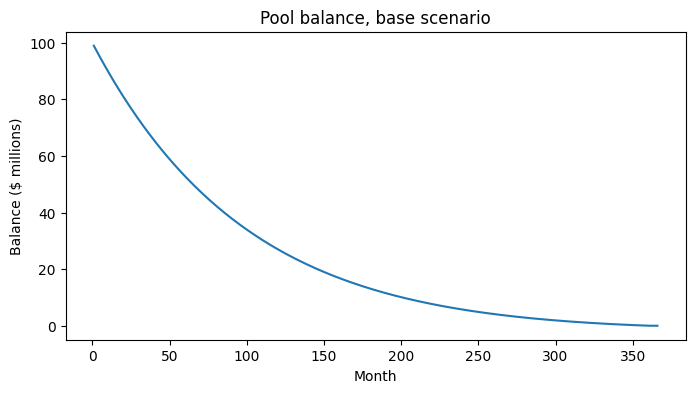

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(pool.index, pool["ending_balance"] / 1e6)
plt.title("Pool balance, base scenario")
plt.xlabel("Month")
plt.ylabel("Balance ($ millions)")
plt.show()

## Waterfall, month 1 by hand

The waterfall decides who gets the pool cash each month. The variable names below are the same as in run_waterfall, so the two can be read side by side. First the servicing fee is taken out of the pool interest.

In [13]:
pool_row = pool.loc[1]
servicing_fee = min(pool_row["beginning_balance"] * DEAL["servicing_fee_rate"] / 12, pool_row["interest"])
interest_cash = pool_row["interest"] - servicing_fee
print(f"servicing fee = {servicing_fee:,.2f}   interest cash left = {interest_cash:,.2f}")

servicing fee = 41,666.67   interest cash left = 541,178.31


Class A interest is paid next, then class B. Each class is due its balance times its coupon over 12. Whatever is not paid is a shortfall, recorded and not carried forward.

In [14]:
a_balance = DEAL["a_balance"]
a_interest_due = a_balance * DEAL["a_coupon"] / 12
a_interest_paid = min(a_interest_due, interest_cash)
interest_cash = interest_cash - a_interest_paid

b_balance = DEAL["b_balance"]
b_interest_due = b_balance * DEAL["b_coupon"] / 12
b_interest_paid = min(b_interest_due, interest_cash)
interest_cash = interest_cash - b_interest_paid
print(f"A interest = {a_interest_paid:,.2f}   B interest = {b_interest_paid:,.2f}   left = {interest_cash:,.2f}")

A interest = 333,333.33   B interest = 47,916.67   left = 159,928.31


After B interest the deal checks two coverage tests on beginning-of-month balances. OC is over-collateralization: pool balance plus recoveries pending, divided by the A and B balances, trigger 108%. IC is interest coverage: pool interest after the fee, divided by A and B interest due, trigger 125%. In this first pass the tests are switched off, so they are only reported.

In [15]:
recoveries_pending_beginning = 0.0
oc_ratio = (pool_row["beginning_balance"] + recoveries_pending_beginning) / (a_balance + b_balance)
ic_ratio = (pool_row["interest"] - servicing_fee) / (a_interest_due + b_interest_due)
tests_pass = oc_ratio >= DEAL["oc_trigger"] and ic_ratio >= DEAL["ic_trigger"]
print(f"OC = {oc_ratio:.4f}   IC = {ic_ratio:.4f}   tests pass = {tests_pass}")

OC = 1.1111   IC = 1.4195   tests pass = True


Class C interest is paid next. The remaining interest cash goes to the residual, which has no coupon.

In [16]:
c_balance = DEAL["c_balance"]
c_interest_due = c_balance * DEAL["c_coupon"] / 12
c_interest_paid = min(c_interest_due, interest_cash)
residual_interest = interest_cash - c_interest_paid
print(f"C interest = {c_interest_paid:,.2f}   residual interest = {residual_interest:,.2f}")

C interest = 32,500.00   residual interest = 127,428.31


Principal cash is scheduled principal plus prepayments plus recoveries received. It pays A until A is gone, then B, then C, then the residual.

In [17]:
principal_cash = pool_row["scheduled_principal"] + pool_row["prepayment"] + pool_row["recovery_received"]
a_principal_paid = min(a_balance, principal_cash)
b_principal_paid = min(b_balance, principal_cash - a_principal_paid)
c_principal_paid = min(c_balance, principal_cash - a_principal_paid - b_principal_paid)
residual_principal = principal_cash - a_principal_paid - b_principal_paid - c_principal_paid
a_balance = a_balance - a_principal_paid
b_balance = b_balance - b_principal_paid
c_balance = c_balance - c_principal_paid
print(f"principal cash = {principal_cash:,.2f}   paid to A = {a_principal_paid:,.2f}   A balance = {a_balance:,.2f}")

principal cash = 954,613.86   paid to A = 954,613.86   A balance = 79,045,386.14


Last, the write-down. Collateral is the ending pool balance plus recoveries still to come. If the notes A + B + C are larger than the collateral, the excess is written off C first, then B, then A. In month 1 the $4 million residual still covers the small loss, so nothing is written down.

In [18]:
collateral = pool_row["ending_balance"] + pool_row["recoveries_pending"]
excess_notes = max(a_balance + b_balance + c_balance - collateral, 0.0)
c_writedown = min(c_balance, excess_notes)
b_writedown = min(b_balance, excess_notes - c_writedown)
a_writedown = min(a_balance, excess_notes - c_writedown - b_writedown)
print(f"collateral = {collateral:,.2f}   notes = {a_balance + b_balance + c_balance:,.2f}   write-down = {c_writedown + b_writedown + a_writedown:,.2f}")

collateral = 99,016,084.93   notes = 95,045,386.14   write-down = 0.00


run_waterfall repeats these steps for every month. Its first row should match.

In [19]:
waterfall = run_waterfall(DEAL, pool, tests_on=False)
waterfall.loc[[1]].T

month,1
servicing_fee,"41,666.67"
a_interest_due,"333,333.33"
a_interest_paid,"333,333.33"
a_interest_shortfall,0.00
b_interest_due,"47,916.67"
b_interest_paid,"47,916.67"
b_interest_shortfall,0.00
oc_ratio,1.11
ic_ratio,1.42
tests_pass,True


## Waterfall, all months

A few months across the life of the deal. Principal goes to A until it is repaid, then to B, then to C.

In [20]:
columns = ["a_principal_paid", "b_principal_paid", "c_principal_paid", "residual_principal",
           "a_balance", "b_balance", "c_balance"]
waterfall.loc[[1, 60, 120, 180, 240, 300, 360], columns]

,a_principal_paid,b_principal_paid,c_principal_paid,residual_principal,a_balance,b_balance,c_balance
month,,,,,,,
1,"954,613.86",0.00,0.00,0.00,"79,045,386.14","10,000,000.00","6,000,000.00"
60,"562,627.01",0.00,0.00,0.00,"34,348,411.76","10,000,000.00","6,000,000.00"
120,"306,690.93",0.00,0.00,0.00,"9,144,930.57","10,000,000.00","6,000,000.00"
180,0.00,"164,856.85",0.00,0.00,0.00,"5,487,354.55","6,000,000.00"
240,0.00,0.00,"86,711.96",0.00,0.00,0.00,"4,212,346.30"
300,0.00,0.00,"44,025.43",0.00,0.00,0.00,"441,037.74"
360,0.00,0.00,0.00,"21,006.70",0.00,0.00,0.00


Chart 2: tranche balances over time.

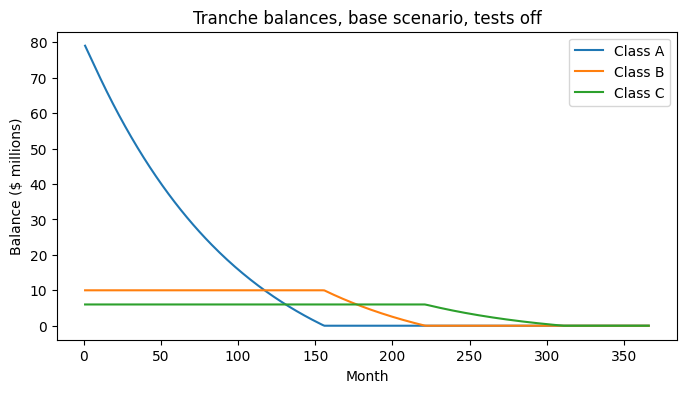

In [21]:
plt.figure(figsize=(8, 4))
for tranche in ["a", "b", "c"]:
    plt.plot(waterfall.index, waterfall[tranche + "_balance"] / 1e6, label="Class " + tranche.upper())
plt.title("Tranche balances, base scenario, tests off")
plt.xlabel("Month")
plt.ylabel("Balance ($ millions)")
plt.legend()
plt.show()

Results per tranche. WAL is the weighted average life: the average time until principal is received, weighted by the amount received, in years. In the base case no class is written down.

In [22]:
summarize_tranches(DEAL, waterfall)

,original_balance,principal_paid,writedown,writedown_pct,wal_years,interest_shortfall
tranche,,,,,,
A,80000000,"80,000,000.00",0.00,0.00,4.92,0.00
B,10000000,"10,000,000.00",0.00,0.00,15.44,0.00
C,6000000,"6,000,000.00",0.00,0.00,21.60,0.00


## Coverage tests switched on

With tests_on=True, a failed test redirects the interest left after B to pay down A principal, and C and the residual get nothing that month. In the base case both tests pass every month, so nothing changes.

In [23]:
waterfall_tests_on = run_waterfall(DEAL, pool, tests_on=True)
print("months with a failed test:", int((waterfall_tests_on["tests_pass"] == False).sum()))
summarize_tranches(DEAL, waterfall_tests_on)

months with a failed test: 0


,original_balance,principal_paid,writedown,writedown_pct,wal_years,interest_shortfall
tranche,,,,,,
A,80000000,"80,000,000.00",0.00,0.00,4.92,0.00
B,10000000,"10,000,000.00",0.00,0.00,15.44,0.00
C,6000000,"6,000,000.00",0.00,0.00,21.60,0.00


To see the tests do something, run the combined scenario (slow prepayments, high defaults, high severity) with tests off and with tests on.

In [24]:
combined = SCENARIOS["combined"]
pool_combined = run_pool(DEAL, combined["cpr"], combined["cdr"], combined["severity"])
combined_tests_off = run_waterfall(DEAL, pool_combined, tests_on=False)
combined_tests_on = run_waterfall(DEAL, pool_combined, tests_on=True)
print("months with a failed test:", int((combined_tests_on["tests_pass"] == False).sum()))
print(f"interest redirected to principal over the life: {combined_tests_on['redirected_interest'].sum():,.0f}")

months with a failed test: 142
interest redirected to principal over the life: 5,853,478


The first month a test fails, and where the cash goes in that month.

In [25]:
first_failed_month = combined_tests_on.index[combined_tests_on["tests_pass"] == False][0]
combined_tests_on.loc[[first_failed_month]].T

month,37
servicing_fee,"31,537.14"
a_interest_due,"252,593.96"
a_interest_paid,"252,593.96"
a_interest_shortfall,0.00
b_interest_due,"47,916.67"
b_interest_paid,"47,916.67"
b_interest_shortfall,0.00
oc_ratio,1.08
ic_ratio,1.36
tests_pass,False


Write-down as a percent of original balance, tests off and tests on. Redirecting interest keeps cash in the deal, which protects B.

In [26]:
pd.DataFrame({
    "tests off": summarize_tranches(DEAL, combined_tests_off)["writedown_pct"],
    "tests on": summarize_tranches(DEAL, combined_tests_on)["writedown_pct"],
})

,tests off,tests on
tranche,,
A,0.00,0.00
B,54.76,0.00
C,100.00,93.70


Chart 3: the OC ratio against its 108% trigger. In the base case it only rises as A pays down. In the combined scenario with tests off it falls through the trigger; with tests on it is held near the trigger because each failure sends cash to A principal. The y-axis is cut at 125% to keep the trigger readable.

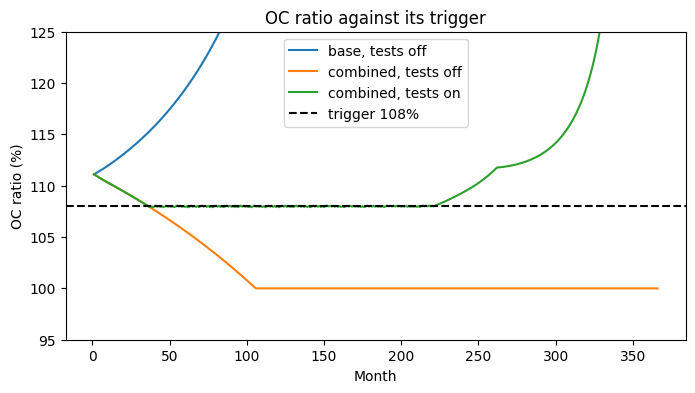

In [27]:
plt.figure(figsize=(8, 4))
plt.plot(waterfall.index, 100 * waterfall["oc_ratio"], label="base, tests off")
plt.plot(combined_tests_off.index, 100 * combined_tests_off["oc_ratio"], label="combined, tests off")
plt.plot(combined_tests_on.index, 100 * combined_tests_on["oc_ratio"], label="combined, tests on")
plt.axhline(100 * DEAL["oc_trigger"], color="black", linestyle="--", label="trigger 108%")
plt.title("OC ratio against its trigger")
plt.xlabel("Month")
plt.ylabel("OC ratio (%)")
plt.ylim(95, 125)
plt.legend()
plt.show()

Next: 02_stress_results.ipynb runs all five scenarios and ends with the headline table and chart.